# Домашнее задание. Генеративные модели.

# Установка всего нужного

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from torch.autograd import Variable
from torch.utils.data import DataLoader, TensorDataset

In [2]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE

device(type='cuda')

# Данные

Будем использовать данные телескопа MAGIC из UCI репозитория https://archive.ics.uci.edu/ml/datasets/MAGIC+Gamma+Telescope. Каждый объект в данных - параметры одного изображения кластера и метка этого кластера (фотон или адрон):


0. Length: major axis of ellipse [mm]
1. Width: minor axis of ellipse [mm]
2. Size: 10-log of sum of content of all pixels [in #phot]
3. Conc: ratio of sum of two highest pixels over fSize [ratio]
4. Conc1: ratio of highest pixel over fSize [ratio]
5. Asym: distance from highest pixel to center, projected onto major axis [mm]
6. M3Long: 3rd root of third moment along major axis [mm]
7. M3Trans: 3rd root of third moment along minor axis [mm]
8. Alpha: angle of major axis with vector to origin [deg]
9. Dist: distance from origin to center of ellipse [mm]
10. class: g,h # gamma (signal), hadron (background)

In [3]:
# read data
names = np.array(["Length", "Width", "Size", "Conc", "Conc1", "Asym",
        "M3Long", "M3Trans", "Alpha", "Dist", "class"])
data = pd.read_csv("magic04.data", header=None)
data.columns = names
data.head()

,Length,Width,Size,Conc,Conc1,Asym,M3Long,M3Trans,Alpha,Dist,class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


## Постановка задачи

Ваша задача заключается в том, чтобы с помощью генеративно-состязательных сетей научится генерировать параметры кластеров на изображениях телекопа для каждого типа частиц (фотона или адрона):

- $X$ - матрица реальных объектов, которые нужно начиться генерировать;
- $y$ - метки классов, которые будем использовать как условие при генерации.

In [4]:
# параметры кластеров на изображениях
X = data[names[:-1]].values
X = np.abs(X)

# метки классов
labels = data[names[-1]].values
y = np.ones((len(labels), 1))
y[labels == "h"] = 0

## Визуализация данных

Каждое изображение описывается 10 параметрами. Давайте построим распределения значений каждого параметра для каждого типа частиц.

In [8]:
def plot_hists(X1, X2, names, label1, label2, title, bins=np.linspace(-3, 3, 61)):
    plt.figure(figsize=(4 * 4, 4 * 2))
    plt.suptitle(title)
    for i in range(X1.shape[1]):
        plt.subplot(3, 4, i + 1)
        plt.hist(X1[:, i], bins=bins, alpha=0.5, label=label1, color="C0")
        plt.hist(X2[:, i], bins=bins, alpha=0.5, label=label2, color="C1")
        plt.xlabel(names[i], size=14)
        plt.legend(loc="best")
    plt.tight_layout()
    plt.show()

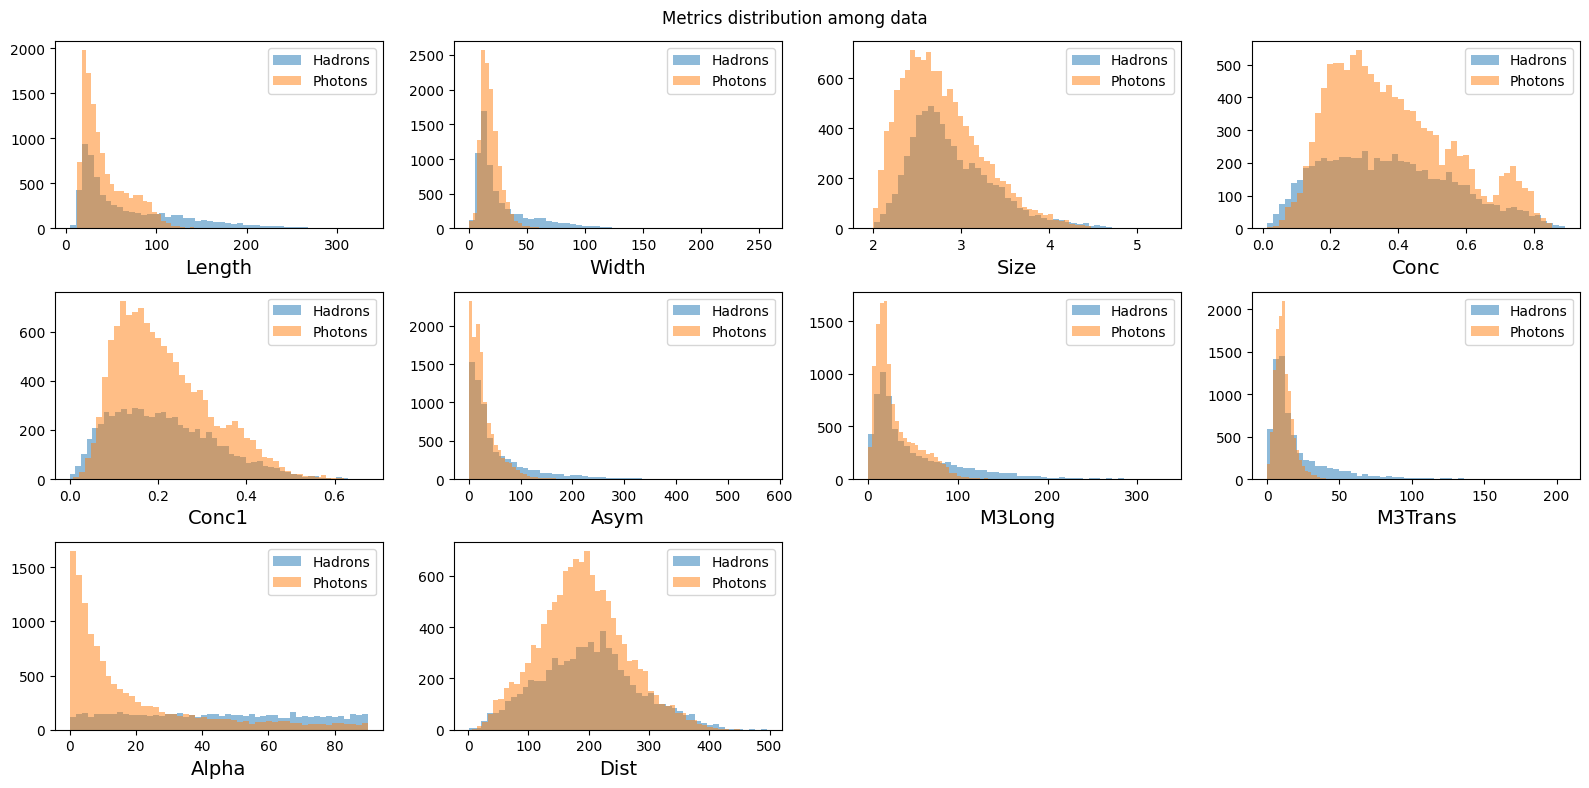

In [9]:
plot_hists(
    X[y[:, 0] == 0], X[y[:, 0] == 1], names, label1="Hadrons", label2="Photons",
    title='Metrics distribution among data', bins=50)

## Предобработка данных

Из графика видим, что распределения для многих признаков имеют тяжелые хвосты. Это делает обучение генеративных моделей тяжелее. Поэтому, нужно как-то преобразовать данные, чтобы убрать эти тяжелые хвосты.

## Задание 1 (0.5 балла)

Используя функцию `sklearn.preprocessing.QuantileTransformer` трансформируйте входные данные `X`. Это преобразование делает так, чтобы распределение каждого параметра было нормальным. Описание функции доступно по ссылке http://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.QuantileTransformer.html. Используйте значение параметра `output_distribution='normal'`.

In [10]:
from sklearn.preprocessing import QuantileTransformer

qt = QuantileTransformer(output_distribution='normal')
X_qt = qt.fit_transform(X)

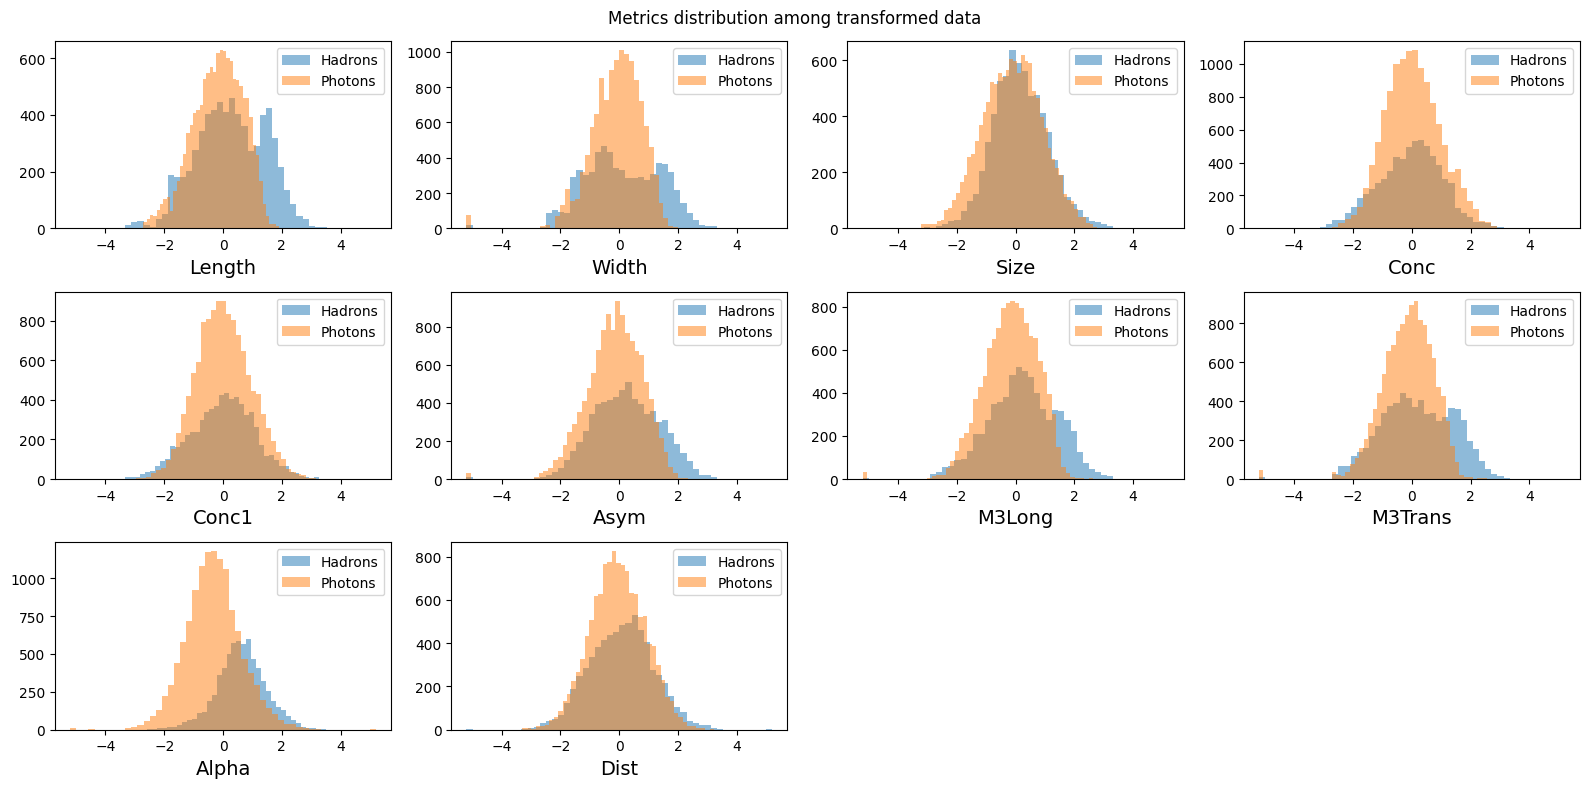

In [11]:
plot_hists(X_qt[y[:, 0] == 0], X_qt[y[:, 0] == 1], names, label1="Hadrons",
           label2="Photons",
           title='Metrics distribution among transformed data', bins=50)

## Обучающая и тестовая выборки

In [12]:
# train / test split
X_train, X_test, y_train, y_test = train_test_split(
    X_qt, y, stratify=y, test_size=0.5, shuffle=True, random_state=11)

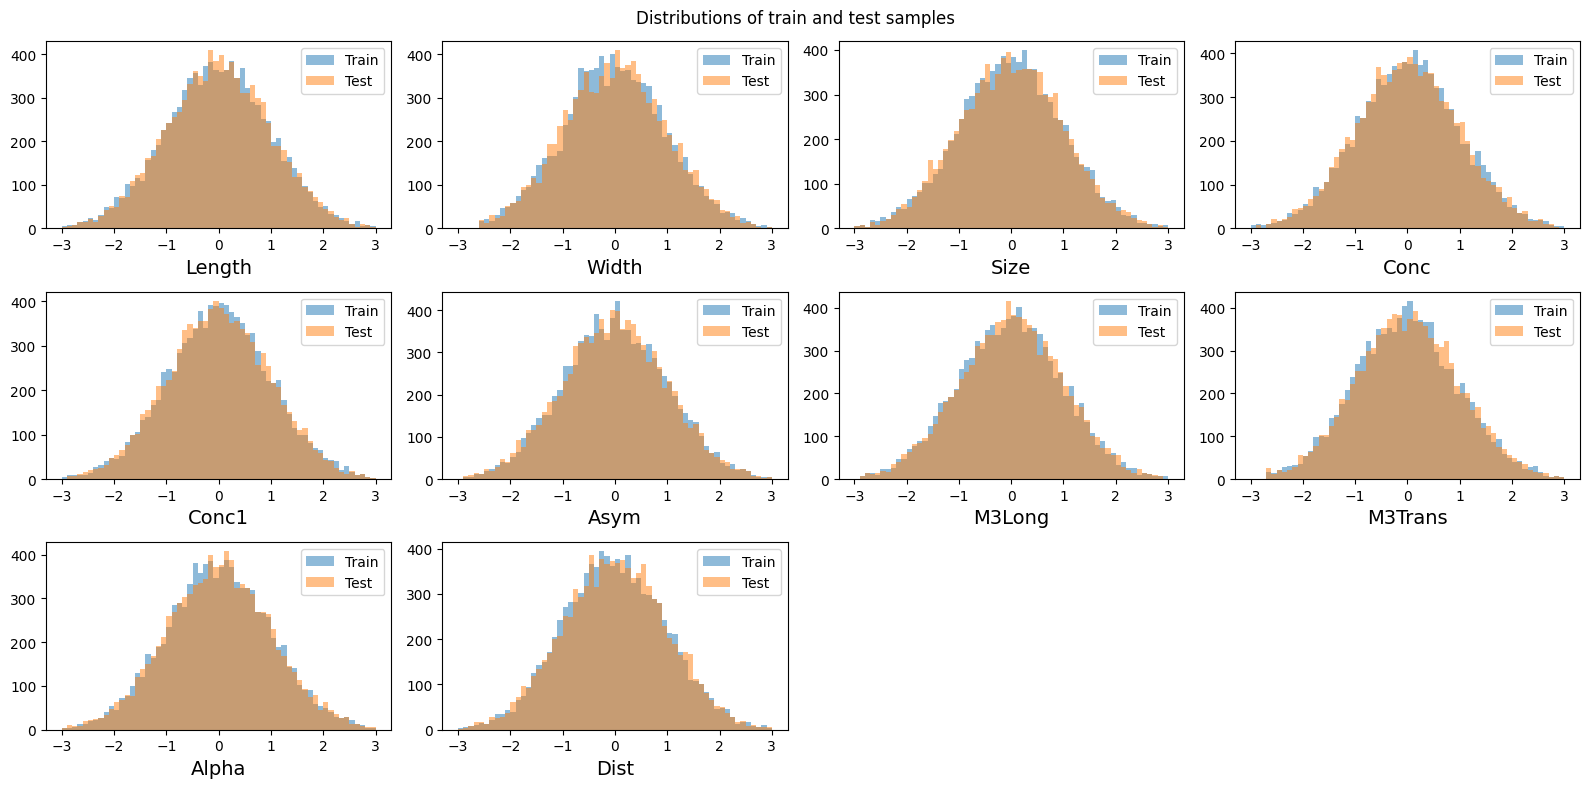

In [13]:
plot_hists(X_train, X_test, names, label1="Train", label2="Test",
           title='Distributions of train and test samples')

# Conditional WGAN

Мы будем использовать `Conditional WGAN`, который изображен на рисунке. В качестве условия `y` мы будем использовать метку класса: **0** - адрон, **1** - фотон. Таким образом, мы будем сообщать генератору для какой частицы нужно генерировать параметры изображения.

<center><img src="img/cgan.png" width="800"></center>

Генератор $\hat{x} = G(z, y)$ будет принимать на вход шумовой вектор $z$ и вектор условий $y$, а выдавать будет сгенерированный (фейковый) вектор параметров $\hat{x}$.

Дискриминатор $D(x, y)$ будет принимать на вход вектор параметров $x$ и вектор условий $y$, а возвращать будет рациональное число.

Обучать `Conditional WGAN` будем с такой функцией потерь:

$$L(G, D) = -\frac{1}{n} \sum_{x_i \in X, y_i \in y} D(x_i, y_i) + \frac{1}{n} \sum_{z_i \in Z, y_i \in y} D(G(z_i, y_i), y_i) \to \max_G \min_D$$

## Задание 2 (0.25 балла)

Реализуйте нейронную сеть для генератора со следующими слоями:
- Полносвязный слой со 100 нейронами;
- Слой батч-нормализации;
- ReLU функцию активации;
- Полносвязный слой со 100 нейронами;
- Слой батч-нормализации;
- ReLU функцию активации;
- Выходной слой.

Подсказка: используйте функцию `nn.Sequential()`.

In [14]:
class Generator(nn.Module):
    def __init__(self, n_inputs, n_outputs):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(n_inputs, 100),
            nn.BatchNorm1d(100),
            nn.ReLU(),
            nn.Linear(100, 100),
            nn.BatchNorm1d(100),
            nn.ReLU(),
            nn.Linear(100, n_outputs)
        )

    def forward(self, z, y):
        zy = torch.cat((z, y), dim=1)
        return self.net(zy)

## Задание 3 (0.25 балла)

Реализуйте нейронную сеть для дискриминатора со следующими слоями:
- Полносвязный слой со 100 нейронами;
- ReLU функцию активации;
- Полносвязный слой со 100 нейронами;
- ReLU функцию активации;
- Выходной слой.

Подсказка: используйте функцию `nn.Sequential()`.

In [15]:
class Discriminator(nn.Module):
    def __init__(self, n_inputs):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(n_inputs, 100),
            nn.ReLU(),
            nn.Linear(100, 100),
            nn.ReLU(),
            nn.Linear(100, 1)
        )

    def forward(self, x, y):
        xy = torch.cat((x, y), dim=1)
        return self.net(xy)

## Задание 4 (1 балл)

Реализуйте класс для обучения генеративной модели.

- Подсказка 1: не забывайте ограничивать веса дискриминатора. Для этого используйте `p.data.clamp_(-0.01, 0.01)`, где `p` веса дискриминатора.
- Подсказка 2: `n_critic` - число итераций обучения дискриминатора на одну итерацию обучения генератора.
- Подсказка 3: Используйте `X_tensor = torch.tensor(X_numpy, dtype=torch.float, device=DEVICE)` для перевода numpy в тензор.

In [16]:
class Fitter(object):
    def __init__(self, generator, discriminator, batch_size=32,
        n_epochs=10, latent_dim=1, lr=0.0001, n_critic=5):

        self.generator = generator
        self.discriminator = discriminator
        self.batch_size = batch_size
        self.n_epochs = n_epochs
        self.latent_dim = latent_dim
        self.lr = lr
        self.n_critic = n_critic

        # Оптимизаторы
        self.opt_gen = torch.optim.RMSprop(self.generator.parameters(), lr=self.lr)
        self.opt_disc = torch.optim.RMSprop(self.discriminator.parameters(), lr=self.lr)

        # Модели генератора и дискриминатора на cuda
        self.generator.to(DEVICE)
        self.discriminator.to(DEVICE)

    def fit(self, X, y):

        # numpy to tensor
        X_real = torch.tensor(X, dtype=torch.float, device=DEVICE)
        y_cond = torch.tensor(y, dtype=torch.float, device=DEVICE)

        # tensor to dataset
        dataset_real = TensorDataset(X_real, y_cond)

        # Turn on training
        self.generator.train(True)
        self.discriminator.train(True)

        self.loss_history = []

        # Fit GAN
        for epoch in range(self.n_epochs):
            for i, (real_batch, cond_batch) in enumerate(
                DataLoader(dataset_real, batch_size=self.batch_size, shuffle=True)):

                # Генерируем новые объекты
                z = torch.normal(0, 1, (len(real_batch), self.latent_dim), device=DEVICE)
                fakes = self.generator(z, cond_batch)

                if (i + 1) % (self.n_critic + 1) == 0: # (i + 1) чтобы сперва подобучился дискриминатор
                    # Раз в n батчей обучаем генератор
                    self.opt_gen.zero_grad()
                    # Стремимся максимизировать то, что выдаёт дискриминатор
                    # (т. е. минимизируем loss)
                    loss = -torch.mean(self.discriminator(fakes, cond_batch))
                    loss.backward()
                    self.opt_gen.step()
                else:
                    # В остальные разы обучаем дискриминатор
                    self.opt_disc.zero_grad()
                    # Стремимся максимизировать то, что выдаёт дискриминатор
                    # на реальных объектах, и минимизировать то, что на
                    # сгенерированных (т. е. минимизируем loss)
                    loss = -torch.mean(self.discriminator(real_batch, cond_batch)) + \
                            torch.mean(self.discriminator(fakes, cond_batch))
                    loss.backward()
                    self.opt_disc.step()

                    # Ограничение весов параметра
                    for p in self.discriminator.parameters():
                        p.data.clamp_(-0.01, 0.01)

            # calculate and store loss after an epoch
            # Генерируем
            Z_noise = torch.normal(0, 1, (len(X_real), self.latent_dim), device=DEVICE)
            X_fake = self.generator(Z_noise, y_cond)
            # Считаем лосс
            loss_epoch = torch.mean(self.discriminator(X_real, y_cond)) - torch.mean(
                self.discriminator(X_fake, y_cond))
            self.loss_history.append(loss_epoch.detach().cpu())

        # Turn off training
        self.generator.train(False)
        self.discriminator.train(False)

## Обучение
Обучим модель на данных.

In [17]:
%%time
latent_dim = 10
generator = Generator(n_inputs=latent_dim + y.shape[1], n_outputs=X_train.shape[1])
discriminator = Discriminator(n_inputs=X_train.shape[1] + y.shape[1])

fitter = Fitter(generator, discriminator, batch_size=50, n_epochs=100,
                latent_dim=latent_dim, lr=0.0001, n_critic=5)
fitter.fit(X_train, y_train)

CPU times: user 1min 8s, sys: 1.56 s, total: 1min 10s
Wall time: 1min 12s


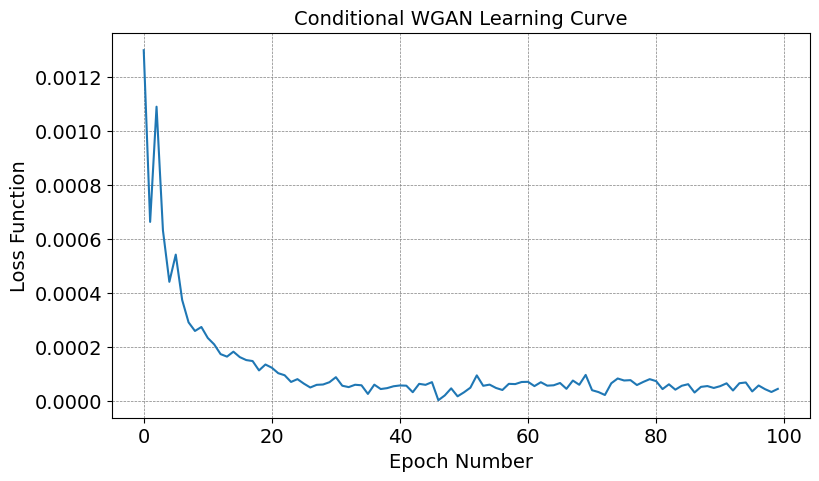

In [18]:
# WGAN learning curve
plt.figure(figsize=(9, 5))
plt.plot(fitter.loss_history)
plt.xlabel("Epoch Number", size=14)
plt.ylabel("Loss Function", size=14)
plt.xticks(size=14)
plt.yticks(size=14)
plt.title("Conditional WGAN Learning Curve", size=14)
plt.grid(visible=True, linestyle="--", linewidth=0.5, color="0.5")
plt.show()

## Задание 5 (0.5 балла)

Реализуйте функцию для генерации новый объектов $X$ по вектору условий $y$.

In [19]:
def generate(generator, y, latent_dim):
    z = torch.normal(0, 1, (len(y), latent_dim), device=DEVICE)
    y = torch.tensor(y, dtype=torch.float, device=DEVICE)
    X_fake = generator(z, y)
    return X_fake.cpu().detach().numpy()

Теперь сгенерируем фейковые матрицы `X_fake_train` и `X_fake_test`. Сравним их с матрицами реальных объектов `X_train` и `X_test`

In [20]:
X_fake_train = generate(fitter.generator, y_train, latent_dim)

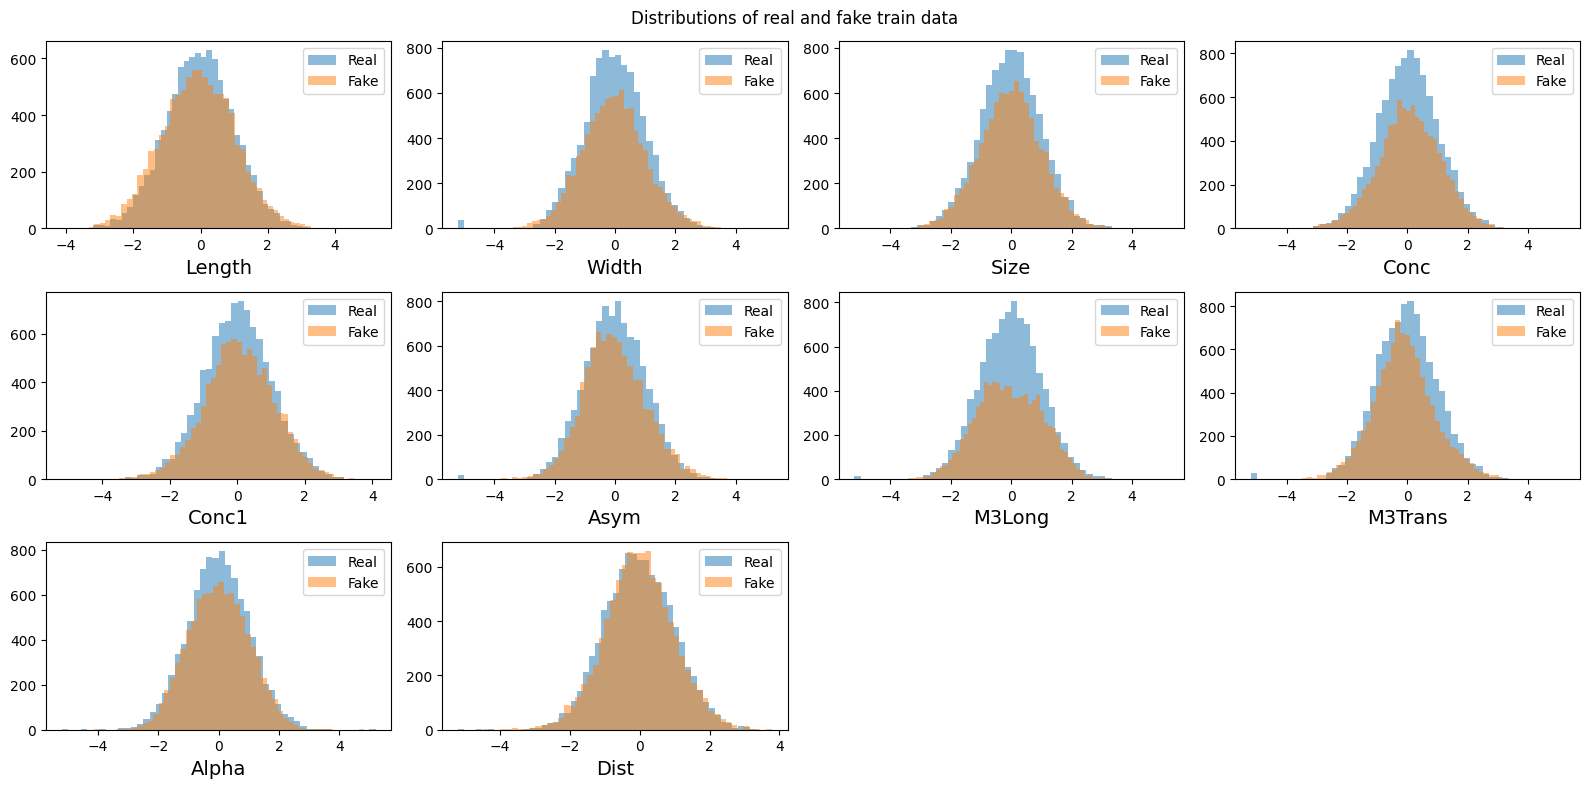

In [22]:
plot_hists(X_train, X_fake_train, names, label1="Real", label2="Fake",
           title='Distributions of real and fake train data', bins=50)

In [23]:
X_fake_test = generate(fitter.generator, y_test, latent_dim)

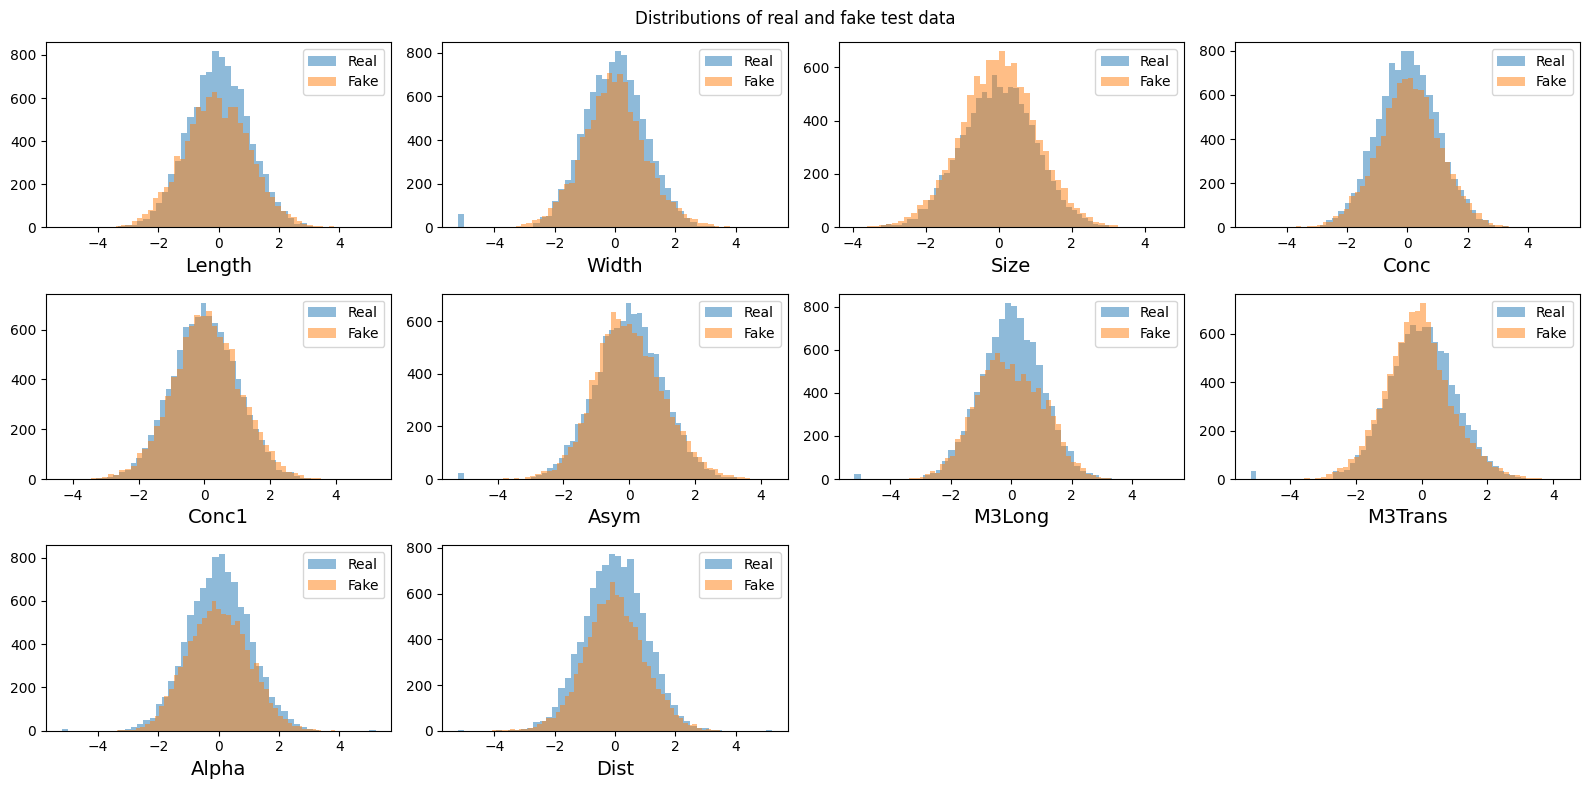

In [24]:
plot_hists(X_test, X_fake_test, names, label1="Real", label2="Fake",
           title='Distributions of real and fake test data', bins=50)

## Измерение качества генерации

Измерим сходство распределений внешним (подумайте почему) классификатором.

Чтобы классификатор заранее не догадывался (не знал никаких параметров), какие картинки реальные, какие фейковые, и мог независимо обучиться их различать без "предрассудков".

In [25]:
# собираем реальную и фейковую матрицы в одну
XX_train = np.concatenate((X_fake_train, X_train), axis=0)
XX_test = np.concatenate((X_fake_test, X_test), axis=0)

yy_train = np.array([0] * len(X_fake_train) + [1] * len(X_train))
yy_test = np.array([0] * len(X_fake_test) + [1] * len(X_test))

In [26]:
# обучаем классификатор
clf = GradientBoostingClassifier()
clf.fit(XX_train, yy_train)

# получаем прогнозы
yy_test_proba = clf.predict_proba(XX_test)[:, 1]

In [27]:
auc = roc_auc_score(yy_test, yy_test_proba)
print("ROC AUC = ", auc)

ROC AUC =  0.7124313827605233


# Условные вариационные автокодировщики

Теперь, решим эту же задачу используя условный автокодировщик (CVAE).

## Задание 6 (0.5 балла)

Реализуйте нейронную сеть для энкодера со следующими слоями:
- Полносвязный слой со 100 нейронами;
- Слой батч-нормализации;
- ReLU функцию активации;
- Полносвязный слой со 100 нейронами;
- Слой батч-нормализации;
- ReLU функцию активации;
- Выходной слой для mu; Выходной слой для log_sigma;

Подсказка: используйте функцию `nn.Sequential()`.

In [28]:
class Encoder(nn.Module):
    def __init__(self, n_inputs, lat_size):
        super().__init__()

        self.enc_net = nn.Sequential(
            nn.Linear(n_inputs, 100),
            nn.BatchNorm1d(100),
            nn.ReLU(),
            nn.Linear(100, 100),
            nn.BatchNorm1d(100),
            nn.ReLU()
        )

        self.mu = nn.Linear(100, lat_size)
        self.log_sigma = nn.Linear(100, lat_size)

    def forward(self, x, y):
        z = torch.cat((x, y), dim=1)
        z = self.enc_net(z)
        mu = self.mu(z)
        log_sigma = self.log_sigma(z)
        return mu, log_sigma

## Задание 7 (0.5 балла)

Реализуйте нейронную сеть для декодера со следующими слоями:
- Полносвязный слой со 100 нейронами;
- ReLU функцию активации;
- Полносвязный слой со 100 нейронами;
- ReLU функцию активации;
- Выходной слой.

Подсказка: используйте функцию `nn.Sequential()`.

In [29]:
class Decoder(nn.Module):
    def __init__(self, n_inputs, n_outputs):
        super().__init__()

        self.dec_net = nn.Sequential(
            nn.Linear(n_inputs, 100),
            nn.ReLU(),
            nn.Linear(100, 100),
            nn.ReLU(),
            nn.Linear(100, n_outputs)
        )

    def forward(self, z, y):
        z_cond = torch.cat((z, y), dim=1)
        x_rec = self.dec_net(z_cond)
        return x_rec

## Задание 8 (0.5 балл)

Реализуйте класс для обучения вариационного автокодировщика.

In [30]:
class VAEFitter:
    def __init__(self, encoder, decoder, batch_size=32, n_epochs=10,
        latent_dim=1, lr=0.0001, KL_weight=0.001):

        self.encoder = encoder
        self.decoder = decoder
        self.batch_size = batch_size
        self.n_epochs = n_epochs
        self.latent_dim = latent_dim
        self.lr = lr
        self.KL_weight = KL_weight

        self.criterion = nn.MSELoss()
        self.opt = torch.optim.RMSprop(
            list(self.encoder.parameters()) + list(self.decoder.parameters()),
            lr=self.lr)

        self.encoder.to(DEVICE)
        self.decoder.to(DEVICE)

    # Распределение с нужным средним и среднеквадратическим отклонением
    def sample_z(self, mu, log_sigma):
        eps = torch.randn(mu.shape).to(DEVICE)
        return mu + torch.exp(log_sigma / 2) * eps

    # Добавляем в Loss умную KL-дивергенцию
    def custom_loss(self, x, rec_x, mu, log_sigma):
        KL = torch.mean(
            -0.5 * torch.sum(1 + log_sigma - mu**2 - log_sigma.exp(), dim=1), dim=0)
        # MSE
        recon_loss = self.criterion(x, rec_x)
        return KL * self.KL_weight + recon_loss

    # Собираем всё вместе для подсчёта лосса
    def compute_loss(self, x_batch, cond_batch):
        mu, log_sigma = self.encoder(x_batch, cond_batch)
        z = self.sample_z(mu, log_sigma)
        rec_x = self.decoder(z, cond_batch)

        loss = self.custom_loss(x_batch, rec_x, mu, log_sigma)

        return loss

    def fit(self, X, y):

        # numpy to tensor
        X_real = torch.tensor(X, dtype=torch.float, device=DEVICE)
        y_cond = torch.tensor(y, dtype=torch.float, device=DEVICE)

        # tensor to dataset
        dataset_real = TensorDataset(X_real, y_cond)

        # Turn on training
        self.encoder.train(True)
        self.decoder.train(True)

        self.loss_history = []

        # Fit CVAE
        for epoch in range(self.n_epochs):
            for i, (x_batch, cond_batch) in enumerate(
                DataLoader(dataset_real, batch_size=self.batch_size, shuffle=True)):

                # calculate loss
                loss = self.compute_loss(x_batch, cond_batch)

                # optimization step
                self.opt.zero_grad()
                loss.backward()
                self.opt.step()

            # calculate and store loss after an epoch
            loss_epoch = self.compute_loss(X_real, y_cond)
            self.loss_history.append(loss_epoch.detach().cpu())

        # Turn off training
        self.encoder.train(False)
        self.decoder.train(False)

## Обучение
Обучим модель на данных.

In [31]:
%%time
latent_dim = 10

encoder = Encoder(n_inputs=X_train.shape[1] + y.shape[1], lat_size=latent_dim)
decoder = Decoder(n_inputs=latent_dim + y.shape[1], n_outputs=X_train.shape[1])

vae_fitter = VAEFitter(encoder, decoder, batch_size=50, n_epochs=200, # на 100 эпохах был отвратительный график обучения
      latent_dim=latent_dim, lr=0.001, KL_weight=0.001)               # правда на 200 не особо лучше...

vae_fitter.fit(X_train, y_train)

CPU times: user 2min 18s, sys: 2.07 s, total: 2min 20s
Wall time: 2min 23s


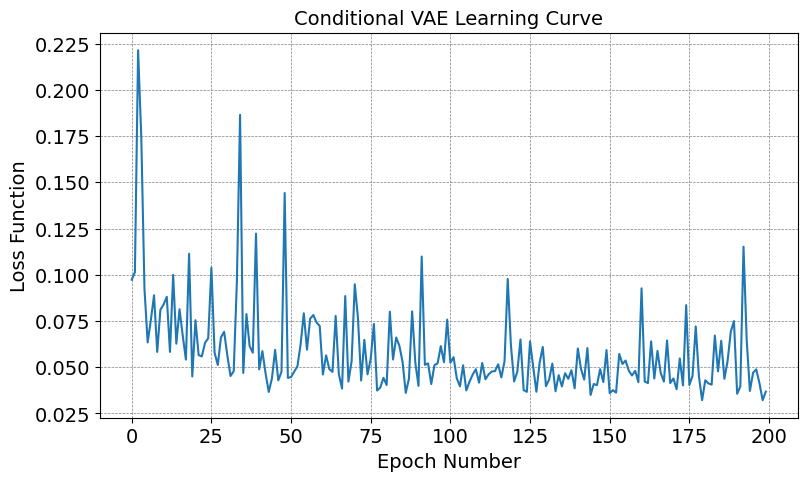

In [32]:
# WGAN learning curve
plt.figure(figsize=(9, 5))
plt.plot(vae_fitter.loss_history)
plt.xlabel("Epoch Number", size=14)
plt.ylabel("Loss Function", size=14)
plt.xticks(size=14)
plt.yticks(size=14)
plt.title("Conditional VAE Learning Curve", size=14)
plt.grid(visible=True, linestyle="--", linewidth=0.5, color="0.5")
plt.show()

## Задание 9 (0.5 балл)

Реализуйте функцию для генерации новый объектов $X$ по вектору условий $y$.

In [33]:
def generate(decoder, y, latent_dim):
    z = torch.normal(0, 1, (len(y), latent_dim), device=DEVICE)
    y = torch.tensor(y, dtype=torch.float, device=DEVICE)
    X_fake = decoder(z, y)
    return X_fake.cpu().detach().numpy()

Теперь сгенерируем фейковые матрицы `X_fake_train` и `X_fake_test`. Сравним их с матрицами реальных объектов `X_train` и `X_test`

In [34]:
X_fake_train = generate(vae_fitter.decoder, y_train, latent_dim)

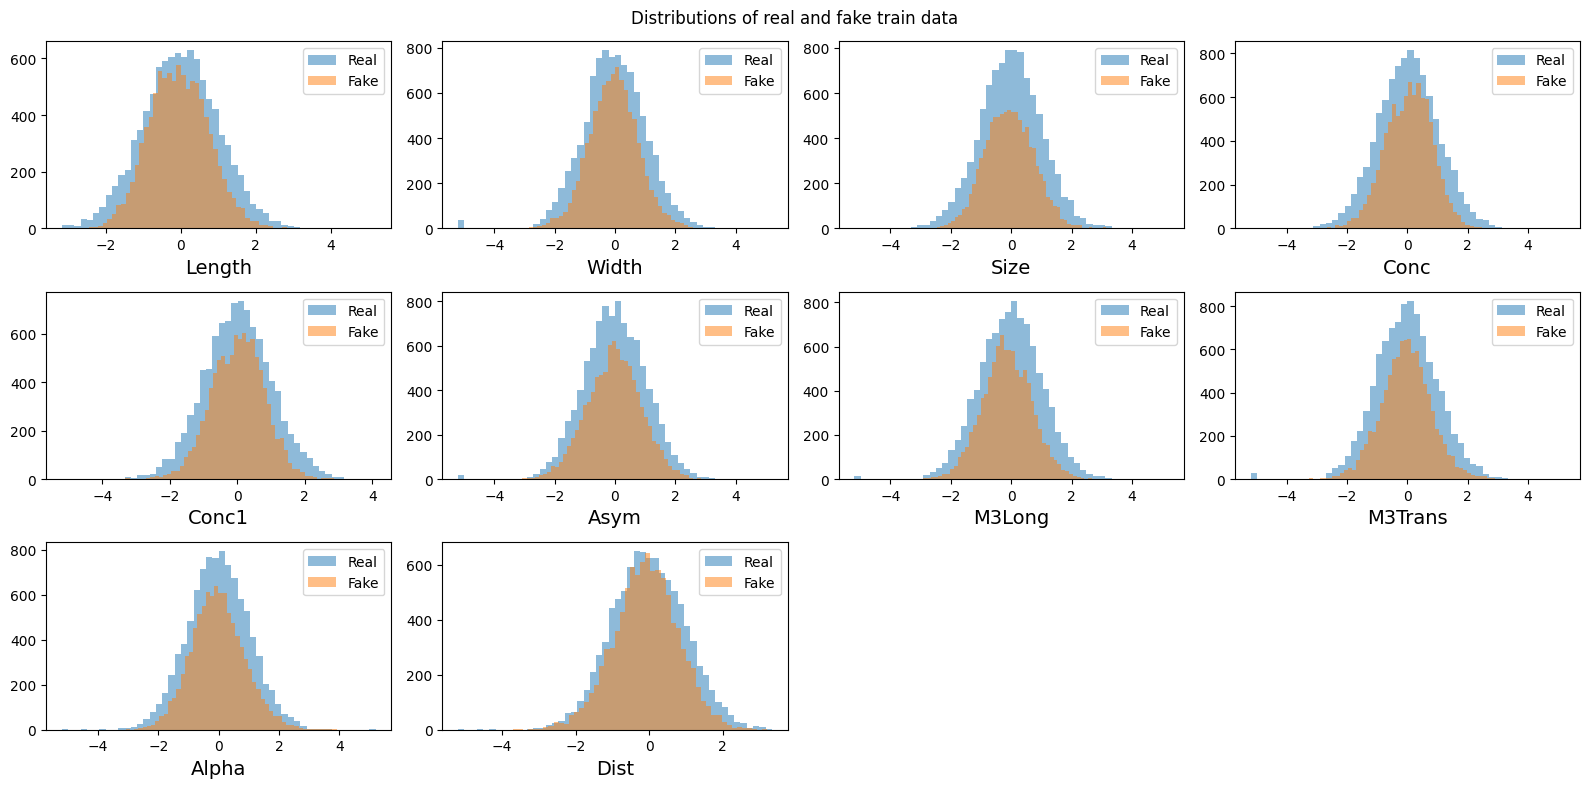

In [35]:
plot_hists(X_train, X_fake_train, names, label1="Real", label2="Fake",
           title='Distributions of real and fake train data', bins=50)

In [36]:
X_fake_test = generate(vae_fitter.decoder, y_test, latent_dim)

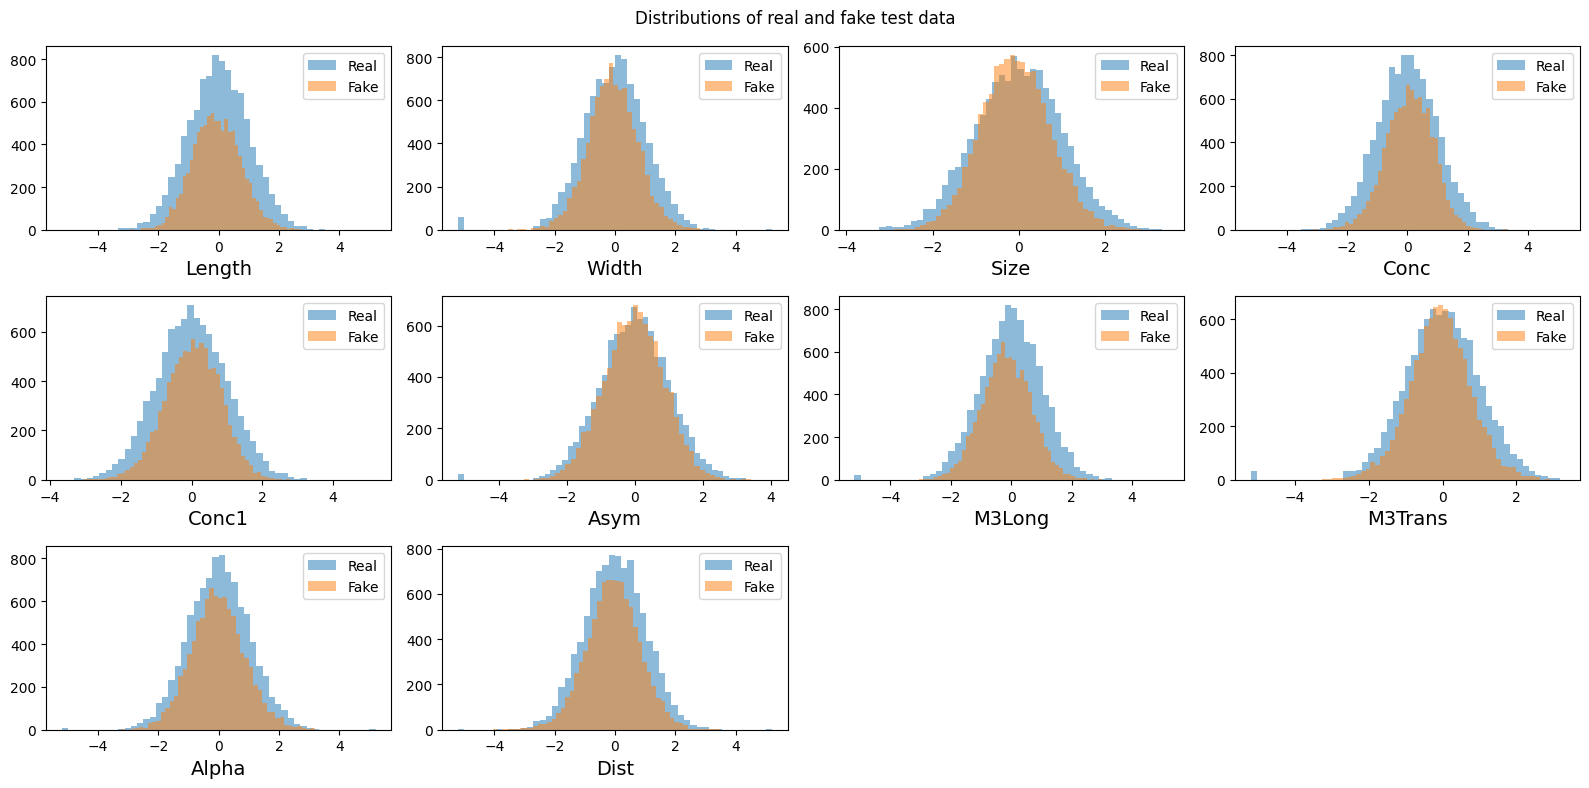

In [37]:
plot_hists(X_test, X_fake_test, names, label1="Real", label2="Fake",
           title='Distributions of real and fake test data', bins=50)

## Измерение качества генерации

Измерим сходство распределений классификатором.

In [38]:
# собираем реальную и фейковую матрицы в одну
XX_train = np.concatenate((X_fake_train, X_train), axis=0)
XX_test = np.concatenate((X_fake_test, X_test), axis=0)

yy_train = np.array([0] * len(X_fake_train) + [1] * len(X_train))
yy_test = np.array([0] * len(X_fake_test) + [1] * len(X_test))

In [39]:
# обучаем классификатор
clf = GradientBoostingClassifier()
clf.fit(XX_train, yy_train)

# получаем прогнозы
yy_test_proba = clf.predict_proba(XX_test)[:, 1]

In [40]:
auc = roc_auc_score(yy_test, yy_test_proba)
print("ROC AUC = ", auc)

ROC AUC =  0.6808354203500439


# Диффузионные модели

Все то же самое, что и выше, но теперь диффузионки

In [ ]:
!pip install diffusers -q

In [41]:
from diffusers import DDPMScheduler

## Задание 10 (0.5 балла)

Реализуйте фукнцию для зашумления данных, адаптировав ее под наш тип данных.

In [ ]:
def corrupt(x, amount):
    noise = torch.rand_like(x)
    amount = amount.view(-1, 1)
    return x * (1 - amount) + noise * amount

Совет: прочтите доку на шедулер, то как он объявлен ниже может быть неоптимально для наших данных (потому что у нас не картинки!) :)

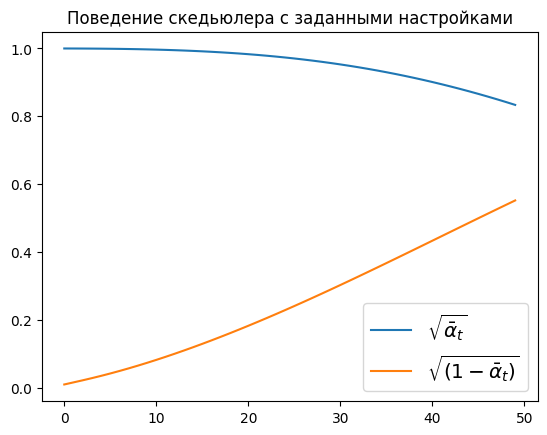

In [42]:
# Ровно такая комбинация параметров в скедьюлере даёт лучший ROC-AUC
noise_scheduler = DDPMScheduler(num_train_timesteps=50,
                                beta_schedule="scaled_linear")
plt.plot(
    noise_scheduler.alphas_cumprod.cpu() ** 0.5, label=r"${\sqrt{\bar{\alpha}_t}}$")
plt.plot(
    (1 - noise_scheduler.alphas_cumprod.cpu()) ** 0.5,
    label=r"$\sqrt{(1 - \bar{\alpha}_t)}$")
plt.legend(fontsize="x-large")
plt.title('Поведение скедьюлера с заданными настройками')
plt.show()

## Задание 11 (0.5 балла)

Реализуйте нейронную сеть. В качетсве архитектуры можете взять модель генератора. В процессе экспериментов попробуйте изменять архитектуру модели для улучшения качества сгенерированных объектов.

- Полносвязный слой со 100 нейронами;
- Слой батч-нормализации;
- ReLU функцию активации;
- Полносвязный слой со 100 нейронами;
- Слой батч-нормализации;
- ReLU функцию активации;
- Выходной слой.

In [ ]:
class DiffusionGenerator(nn.Module):
    def __init__(self, n_inputs, n_outputs):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(n_inputs, 100),
            nn.BatchNorm1d(100),
            nn.ReLU(),
            nn.Linear(100, 100),
            nn.BatchNorm1d(100),
            nn.ReLU(),
            nn.Linear(100, n_outputs)
        )

    def forward(self, z, y):
        zy = torch.cat((z, y), dim=1)
        return self.net(zy)

## Задание 12 (0.5 балла)

Напишите функцию для генерации нового объекта с помощью обученной модели.

In [ ]:
def generate_with_diffusion(model, y, latent_dim, scheduler):
    y = torch.tensor(y, dtype=torch.float, device=DEVICE)
    # Генерируем вектор нужной размерности
    z = torch.normal(0, 1, (len(y), latent_dim), device=DEVICE)
    # Генерируем шум с нужным распределением
    noise = torch.randn_like(z)
    # Добавляем шум к вектору
    noisy_z = scheduler.add_noise(z, noise, torch.randint(0, 49, (len(y),), device=DEVICE))

    X_fake = model(noisy_z, y)
    return X_fake.cpu().detach().numpy()

## Задание 13 (1 балла)

Напишите класс обучения диффузионной модели и обучите модель, после чего опишите полученные результаты. Вы можете изменять некоторые части кода для вашего удобства, но оставляйте в таком случаи комментарии, пожалуйста.

In [ ]:
class DiffusionFitter:
    def __init__(self, model, scheduler=noise_scheduler, batch_size=32,
                 n_epochs=10, latent_dim=1, lr=0.0001, n_critic=5):

        self.model = model
        self.batch_size = batch_size
        self.n_epochs = n_epochs
        self.latent_dim = latent_dim
        self.lr = lr
        self.n_critic = n_critic

        self.opt_gen = torch.optim.RMSprop(self.model.parameters(), lr=self.lr)
        # Объявим сразу здесь MSELoss
        self.loss_func = nn.MSELoss()
        # Объявим scheduler для зашумления данных
        self.scheduler = scheduler

        self.model.to(DEVICE)

    def fit(self, X, y):

        # numpy to tensor
        X_real = torch.tensor(X, dtype=torch.float, device=DEVICE)
        y_cond = torch.tensor(y, dtype=torch.float, device=DEVICE)

        # tensor to dataset
        dataset_real = TensorDataset(X_real, y_cond)

        # Turn on training
        self.model.train(True)

        self.loss_history = []

        # Fit
        for epoch in range(self.n_epochs):
            loss_epoch = 0
            for i, (real_batch, cond_batch) in enumerate(
                DataLoader(dataset_real, batch_size=self.batch_size, shuffle=True)):
                # Добавляем шум к вектору
                noisy_x = self.scheduler.add_noise(real_batch, torch.randn_like(real_batch),
                                                   torch.randint(0, 49, (len(real_batch),)).long())
                # Делаем предсказания из зашумлённого x
                pred = self.model(noisy_x, cond_batch)

                loss = self.loss_func(pred, real_batch)
                self.opt_gen.zero_grad()
                loss.backward()
                self.opt_gen.step()

                loss_epoch += loss.item()

            # calculate and store loss after an epoch
            self.loss_history.append(loss_epoch)

        # Turn off training
        self.model.train(False)

In [ ]:
%%time
latent_dim = 10
model = DiffusionGenerator(n_inputs=latent_dim + y.shape[1], n_outputs=X_train.shape[1])

diffusionFitter = DiffusionFitter(model, batch_size=50, n_epochs=100,
    latent_dim=latent_dim, lr=0.0001, n_critic=5)
diffusionFitter.fit(X_train, y_train)

CPU times: user 47.5 s, sys: 748 ms, total: 48.3 s
Wall time: 48.7 s


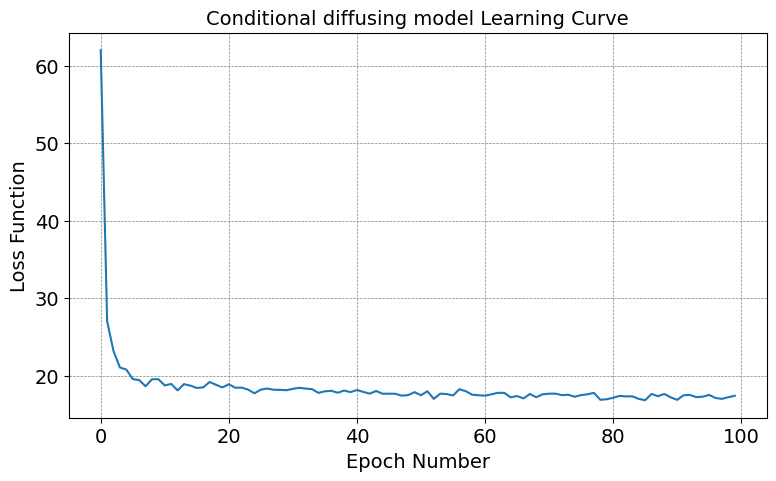

In [ ]:
# diffusion learning curve
plt.figure(figsize=(9, 5))
plt.plot(diffusionFitter.loss_history)
plt.xlabel("Epoch Number", size=14)
plt.ylabel("Loss Function", size=14)
plt.xticks(size=14)
plt.yticks(size=14)
plt.title("Conditional diffusing model Learning Curve", size=14)
plt.grid(visible=True, linestyle="--", linewidth=0.5, color="0.5")
plt.show()

## Задание 14 (0.5 балла)
По аналогии с прошлыми экспериментами с GAN моделью сгенерируйте выборку фейковых объектов, равную размеру тестовой выборки, и обучите градиентный бустинг. Обучите модель отличать реальные объекты от фейковых, после чего расчитайте метрику ROC-AUC. Какие получились результаты? Как вы их оцениваете? А в сравнении с сWGAN моделью?

In [ ]:
X_fake_train = generate_with_diffusion(diffusionFitter.model, y_train,
                                       latent_dim, diffusionFitter.scheduler)
X_fake_test = generate_with_diffusion(diffusionFitter.model, y_test,
                                      latent_dim, diffusionFitter.scheduler)

# собираем реальную и фейковую матрицы в одну
XX_train = np.concatenate((X_fake_train, X_train), axis=0)
XX_test = np.concatenate((X_fake_test, X_test), axis=0)

yy_train = np.array([0] * len(X_fake_train) + [1] * len(X_train))
yy_test = np.array([0] * len(X_fake_test) + [1] * len(X_test))

# обучаем классификатор
clf = GradientBoostingClassifier()
clf.fit(XX_train, yy_train)

# получаем прогнозы
yy_test_proba = clf.predict_proba(XX_test)[:, 1]

auc = roc_auc_score(yy_test, yy_test_proba)
print("ROC AUC = ", auc)

ROC AUC =  0.8297283450593265


Качество не очень(

# Диффузионная модель: версия без скедьюлера

Ну вдруг тут будет лучше)

In [ ]:
def corrupt(x):
    noise = torch.rand_like(x, device=DEVICE)
    # с тру рандомом лучший рок аук
    amount = torch.rand(x.shape[0], x.shape[1], device=DEVICE)
    return x * (1 - amount) + noise * amount

In [ ]:
class DiffusionGenerator(nn.Module):
    def __init__(self, n_inputs, n_outputs):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(n_inputs, 100),
            nn.BatchNorm1d(100),
            nn.ReLU(),
            nn.Linear(100, 100),
            nn.BatchNorm1d(100),
            nn.ReLU(),
            nn.Linear(100, n_outputs)
        )

    def forward(self, z, y):
        zy = torch.cat((z, y), dim=1)
        return self.net(zy)

In [ ]:
class DiffusionFitter:
    def __init__(self, model, batch_size=32,
                 n_epochs=10, latent_dim=1, lr=0.0001, n_critic=5):

        self.model = model
        self.batch_size = batch_size
        self.n_epochs = n_epochs
        self.latent_dim = latent_dim
        self.lr = lr
        self.n_critic = n_critic

        self.opt_gen = torch.optim.RMSprop(self.model.parameters(), lr=self.lr)
        # Объявим сразу здесь MSELoss
        self.loss_func = nn.MSELoss()

        self.model.to(DEVICE)

    def fit(self, X, y):

        # numpy to tensor
        X_real = torch.tensor(X, dtype=torch.float, device=DEVICE)
        y_cond = torch.tensor(y, dtype=torch.float, device=DEVICE)

        # tensor to dataset
        dataset_real = TensorDataset(X_real, y_cond)

        # Turn on training
        self.model.train(True)

        self.loss_history = []

        # Fit
        for epoch in range(self.n_epochs):
            loss_epoch = 0
            for i, (real_batch, cond_batch) in enumerate(
                DataLoader(dataset_real, batch_size=self.batch_size, shuffle=True)):
                # Добавляем шум к вектору
                noisy_x = corrupt(real_batch)
                # Делаем предсказания из зашумлённого x
                pred = self.model(noisy_x, cond_batch)

                loss = self.loss_func(pred, real_batch)
                self.opt_gen.zero_grad()
                loss.backward()
                self.opt_gen.step()

                loss_epoch += loss.item()

            # calculate and store loss after an epoch
            self.loss_history.append(loss_epoch)

        # Turn off training
        self.model.train(False)

In [ ]:
def generate_with_diffusion(model, y, latent_dim):
    y = torch.tensor(y, dtype=torch.float, device=DEVICE)
    # Генерируем вектор нужной размерности
    z = torch.normal(0, 1, (len(y), latent_dim), device=DEVICE)
    # Корраптим этот вектор к чёртовой бабушке
    noisy_z = corrupt(z)

    X_fake = model(noisy_z, y)
    return X_fake.cpu().detach().numpy()

In [ ]:
%%time
latent_dim = 10
model = DiffusionGenerator(n_inputs=latent_dim + y.shape[1], n_outputs=X_train.shape[1])

diffusionFitter = DiffusionFitter(model, batch_size=50, n_epochs=100,
    latent_dim=latent_dim, lr=0.0001, n_critic=5)
diffusionFitter.fit(X_train, y_train)

CPU times: user 45.1 s, sys: 762 ms, total: 45.9 s
Wall time: 46.3 s


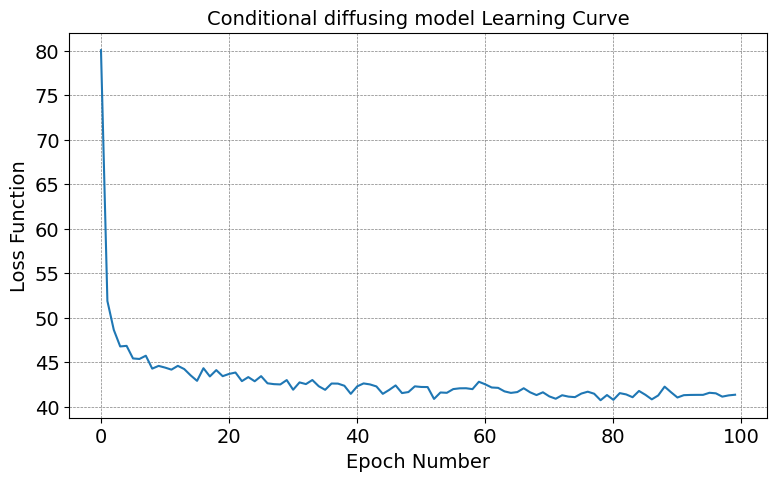

In [ ]:
# diffusion learning curve
plt.figure(figsize=(9, 5))
plt.plot(diffusionFitter.loss_history)
plt.xlabel("Epoch Number", size=14)
plt.ylabel("Loss Function", size=14)
plt.xticks(size=14)
plt.yticks(size=14)
plt.title("Conditional diffusing model Learning Curve", size=14)
plt.grid(visible=True, linestyle="--", linewidth=0.5, color="0.5")
plt.show()

In [ ]:
X_fake_train = generate_with_diffusion(diffusionFitter.model, y_train, latent_dim)
X_fake_test = generate_with_diffusion(diffusionFitter.model, y_test, latent_dim)

# собираем реальную и фейковую матрицы в одну
XX_train = np.concatenate((X_fake_train, X_train), axis=0)
XX_test = np.concatenate((X_fake_test, X_test), axis=0)

yy_train = np.array([0] * len(X_fake_train) + [1] * len(X_train))
yy_test = np.array([0] * len(X_fake_test) + [1] * len(X_test))

# обучаем классификатор
clf = GradientBoostingClassifier()
clf.fit(XX_train, yy_train)

# получаем прогнозы
yy_test_proba = clf.predict_proba(XX_test)[:, 1]

auc = roc_auc_score(yy_test, yy_test_proba)
print("ROC AUC = ", auc)

ROC AUC =  0.7926997537596707


Лучше стало немножко, но не прям-таки сравнимо с GAN

# Нормализационные потоки

## Задание 15 (1 балл)

Диффузия показала себя как достойный конкурент GAN модели. Так как данных не много, обучали не долго, задача не сложная - отличия от GAN не так заметны, но все равно достойные.

Попробуем обучить RealNVP для решения этой задачи.

**Дополните базовый класс необходимым.**

In [ ]:
trainloader = torch.utils.data.DataLoader(X_train, batch_size=64, shuffle=True)

In [ ]:
# Main class for NormFlow
class NormalizingFlow(nn.Module):

    def __init__(self, layers, prior):
        super(NormalizingFlow, self).__init__()
        self.layers = nn.ModuleList(layers)
        self.prior = prior

    # Логарифм правдоподобия объектов
    def log_prob(self, x):
        log_likelihood = None

        for layer in self.layers:
            x, change = layer.f(x)
            if log_likelihood is not None:
                log_likelihood = log_likelihood + change
            else:
                log_likelihood = change

        log_likelihood = log_likelihood + self.prior.log_prob(x)

        return log_likelihood.mean()

    # Сэмплирование/генерирование объектов
    def sample(self, num_samples):
        x = self.prior.sample((num_samples, ))

        for layer in self.layers[::-1]:
            x = layer.g(x)

        return x

## Задание 16 (1 балл)

Реализуйте нейронную сеть RealNVP. Возьмите для прямого и обратного преобразования нейронную сеть (функцию) со следующими параметрами:

- Полносвязный слой со 100 нейронами;
- ReLU функцию активации;
- Выходной слой.

In [ ]:
class RealNVP(nn.Module):
    def __init__(self, var_size, mask, hidden=100):
        super(RealNVP, self).__init__()
        self.mask = mask  # вам это может не понадобиться. Воспринимайте как подсказку
        self.var_size = var_size

        self.nn_t = nn.Sequential(
            nn.Linear(self.var_size, hidden),
            nn.ReLU(),
            nn.Linear(hidden, self.var_size)
        )

        self.nn_s = nn.Sequential(
            nn.Linear(self.var_size, hidden),
            nn.ReLU(),
            nn.Linear(hidden, self.var_size)
        )

    # Прямое преобразование
    def f(self, x):
        # Две нейросети для обработки одного из двух кусков данных
        t = self.nn_t(x * self.mask[None, :])
        s = torch.tanh(self.nn_s(x * self.mask[None, :]))

        # Само преобразование
        new_x = (x * torch.exp(s) + t) * (1 - self.mask[None, :]) + x * self.mask[None, :]

        log_det = (s * (1 - self.mask[None, :])).sum(dim=-1)
        return new_x, log_det

    # Обратное преобразование
    def g(self, x):
        # Две нейросети для обработки одного из двух кусков данных
        t = self.nn_t(x * self.mask[None, :])
        s = torch.tanh(self.nn_s(x * self.mask[None, :]))

        # Само преобразование
        new_x = ((x - t) * torch.exp(-s)) * (1 - self.mask[None, :]) + x * self.mask[None, :]
        return new_x

In [ ]:
def train_nf(tr_dataloader, nf, opt, num_epochs):
    nf.train()
    loss_trace = []

    iter_i = 0

    for epoch_i in range(num_epochs):
        print(f'Epoch {epoch_i + 1}')
        for batch in tr_dataloader:

            x = batch.float()

            opt.zero_grad()

            loss = -nf.log_prob(x)
            loss.backward()

            opt.step()

            loss_trace.append((iter_i, loss.item()))

            iter_i += 1

In [ ]:
prior = torch.distributions.MultivariateNormal(torch.zeros(10), torch.eye(10))

layers = []
for i in range(4):
    layers.append(RealNVP(var_size=10, mask=((torch.arange(10) + i) % 2)))

nf = NormalizingFlow(layers=layers, prior=prior)

opt = torch.optim.Adam(nf.parameters(), lr=1e-3)

In [ ]:
train_nf(trainloader, nf, opt, num_epochs=10)

Epoch 1
Epoch 2
Epoch 3
Epoch 4
Epoch 5
Epoch 6
Epoch 7
Epoch 8
Epoch 9
Epoch 10


## Задание 17 (0.5 балла)

По аналогии с прошлым экспериментом с диффузией сгенерируйте выборку фейковых объектов, равную размеру тестовой выборки, и обучите градиентный бустинг. Обучите модель отличать реальные объекты от фейковых, после чего расчитайте ROC-AUC. Какие получились результаты? Как вы их оцениваете? А в сравнении с остальными моделями?

In [ ]:
X_fake_train = nf.sample(len(X_train)).cpu().detach().numpy()
X_fake_test = nf.sample(len(X_test)).cpu().detach().numpy()

# собираем реальную и фейковую матрицы в одну
XX_train = np.concatenate((X_fake_train, X_train), axis=0)
XX_test = np.concatenate((X_fake_test, X_test), axis=0)

yy_train = np.array([0] * len(X_fake_train) + [1] * len(X_train))
yy_test = np.array([0] * len(X_fake_test) + [1] * len(X_test))

# обучаем классификатор
clf = GradientBoostingClassifier()
clf.fit(XX_train, yy_train)

# получаем прогнозы
yy_test_proba = clf.predict_proba(XX_test)[:, 1]

auc = roc_auc_score(yy_test, yy_test_proba)
print("ROC AUC = ", auc)

ROC AUC =  0.6446187034291205


Вот это я понимаю успех

# Нормализационные потоки с условием

Как-то неправильно, что в изначальном коде мы не добавляем метки 0 и 1 - попробую добавить, вдруг будет ещё лучше

In [ ]:
# Main class for NormFlow
class NormalizingFlow(nn.Module):

    def __init__(self, layers, prior):
        super(NormalizingFlow, self).__init__()
        self.layers = nn.ModuleList(layers)
        self.prior = prior

    # Логарифм правдоподобия объектов
    def log_prob(self, x, y):
        log_likelihood = None

        for layer in self.layers:
            # преобразование с условием
            x, change = layer.f(x, y)
            if log_likelihood is not None:
                log_likelihood = log_likelihood + change
            else:
                log_likelihood = change

        log_likelihood = log_likelihood + self.prior.log_prob(x)

        return log_likelihood.mean()

    # Сэмплирование/генерирование объектов
    def sample(self, num_samples, y_cond):
        x = self.prior.sample((num_samples, ))
        y_cond = torch.tensor(y_cond, dtype=torch.float, device=DEVICE)

        for layer in self.layers[::-1]:
            # обратное преобразование с условием
            x = layer.g(x, y_cond)

        return x

In [ ]:
class RealNVP(nn.Module):
    def __init__(self, var_size, mask, hidden=100):
        super(RealNVP, self).__init__()
        self.mask = mask.to(DEVICE)  # вам это может не понадобиться. Воспринимайте как подсказку
        self.var_size = var_size

        self.nn_t = nn.Sequential(
            nn.Linear(self.var_size + 1, hidden), # чтобы учесть метку класса
            nn.ReLU(),
            nn.Linear(hidden, self.var_size)
        )

        self.nn_s = nn.Sequential(
            nn.Linear(self.var_size + 1, hidden),
            nn.ReLU(),
            nn.Linear(hidden, self.var_size)
        )

    # Прямое преобразование
    def f(self, x, y):
        x_masked = x * self.mask[None, :]
        # Конкатенируем объекты с классом
        x_nn = torch.cat((x_masked, y), dim=1)

        # Две нейросети для обработки одного из двух кусков данных
        # Передаём им данные по маске + классы
        t = self.nn_t(x_nn)
        s = torch.tanh(self.nn_s(x_nn))

        # Само преобразование
        new_x = (x * torch.exp(s) + t) * (1 - self.mask[None, :]) + x_masked

        log_det = (s * (1 - self.mask[None, :])).sum(dim=-1)
        return new_x, log_det

    # Обратное преобразование
    def g(self, x, y):
        x_masked = x * self.mask[None, :]
        # Конкатенируем объекты с классом
        x_nn = torch.cat((x_masked, y), dim=1)

        # Две нейросети для обработки одного из двух кусков данных
        t = self.nn_t(x_nn)
        s = torch.tanh(self.nn_s(x_nn))

        # Само преобразование
        new_x = ((x - t) * torch.exp(-s)) * (1 - self.mask[None, :]) + x_masked
        return new_x

Обучение

In [ ]:
def train_nf(X, y, nf, opt, num_epochs):
    nf.to(DEVICE)
    nf.train()
    loss_trace = []

    iter_i = 0

    # numpy to tensor
    X_real = torch.tensor(X, dtype=torch.float, device=DEVICE)
    y_cond = torch.tensor(y, dtype=torch.float, device=DEVICE)

    # tensor to dataset
    dataset_real = TensorDataset(X_real, y_cond)

    for epoch_i in range(num_epochs):
        print(f'Epoch {epoch_i + 1}')
        # Делаем даталоадер сразу с объектами и метками
        for (real_batch, cond_batch) in DataLoader(dataset_real, batch_size=64, shuffle=True):
            opt.zero_grad()

            loss = -nf.log_prob(real_batch.float(), cond_batch)
            loss.backward()

            opt.step()

            loss_trace.append((iter_i, loss.item()))

            iter_i += 1

In [ ]:
prior = torch.distributions.MultivariateNormal(torch.zeros(10, device=DEVICE),
                                               torch.eye(10, device=DEVICE))

layers = []
for i in range(4):
    layers.append(RealNVP(var_size=10, mask=((torch.arange(10) + i) % 2)))

nf = NormalizingFlow(layers=layers, prior=prior)

opt = torch.optim.Adam(nf.parameters(), lr=1e-3)

train_nf(X_train, y_train, nf, opt, num_epochs=10)

Epoch 1
Epoch 2
Epoch 3
Epoch 4
Epoch 5
Epoch 6
Epoch 7
Epoch 8
Epoch 9
Epoch 10


In [ ]:
X_fake_train = nf.sample(len(y_train), y_train).cpu().detach().numpy()
X_fake_test = nf.sample(len(y_test), y_test).cpu().detach().numpy()

# собираем реальную и фейковую матрицы в одну
XX_train = np.concatenate((X_fake_train, X_train), axis=0)
XX_test = np.concatenate((X_fake_test, X_test), axis=0)

yy_train = np.array([0] * len(X_fake_train) + [1] * len(X_train))
yy_test = np.array([0] * len(X_fake_test) + [1] * len(X_test))

# обучаем классификатор
clf = GradientBoostingClassifier()
clf.fit(XX_train, yy_train)

# получаем прогнозы
yy_test_proba = clf.predict_proba(XX_test)[:, 1]

auc = roc_auc_score(yy_test, yy_test_proba)
print("ROC AUC = ", auc)

ROC AUC =  0.6529893376942307


Эх, добавление условия к сожалению не улучшило правдоподобность изображений

# Эссе по ChatGPT

Для выполнения этого домашнего задания я обращалась за помощью к ChatGPT.

Во-первых, я просила его объяснить мне теоретические нюансы работы моделей, которые мне были непонятны. Например, был такой запрос: "Привет! А расскажи пожалуйста, на каких данных и как обучаются генератор и дискриминатор в Conditional WGAN?" и такой: "А можешь пожалуйста подробнее объяснить timesteps в DDPMScheduler: что это и как понять, какие timesteps мне нужны?"

Во-вторых, я конечно просила его объяснить природу ошибок/неверных результатов и спрашивала способы их исправления. Пример запроса: "Я сделала свой Conditional WGAN, но он очень плохо обучился. Подскажи пожалуйста, может что-то идёт не так в этом коде? /код/"

Я не просила ИИ напрямую сгенерировать мне код, но естественно при ответе на мои вопросы он подкидывал мне куски кода, из которых я могла взять несколько строчек. Например, когда я подправляла нормализующие потоки на conditional, я совершала много ошибок, и их исправления я взяла из ответа ChatGPT.

В общем, некоторые ошибки мне удавалось нагуглить или исправить самой, но чаще всего я обращалась к ИИ за помощью после нескольких неудачных попыток. Генеративный ИИ невероятно помог мне сохранить время и нервы: по моим прикидкам, я сделала это дз раз в 5 быстрее, чем могла бы без ИИ.